##### __Датасет__: "Web page Phishing Detection Dataset"
##### __Посилання на датасет__: https://www.kaggle.com/datasets/shashwatwork/web-page-phishing-detection-dataset
##### __Опис датасету__: The provided dataset includes 11430 URLs with 87 extracted features. The dataset is designed to be used as benchmarks for machine learning-based phishing detection systems. Features are from three different classes: 56 extracted from the structure and syntax of URLs, 24 extracted from the content of their correspondent pages, and 7 are extracted by querying external services. The dataset is balanced, it contains exactly 50% phishing and 50% legitimate URLs.

In [15]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.metrics import precision_score, recall_score, f1_score
from sklearn import set_config
set_config(display="text")

##### Завантаження і первинний аналіз

In [16]:
df = pd.read_csv('lab1/dataset_phishing.csv')

In [17]:
df.shape

(11430, 89)

In [18]:
df.columns

Index(['url', 'length_url', 'length_hostname', 'ip', 'nb_dots', 'nb_hyphens',
       'nb_at', 'nb_qm', 'nb_and', 'nb_or', 'nb_eq', 'nb_underscore',
       'nb_tilde', 'nb_percent', 'nb_slash', 'nb_star', 'nb_colon', 'nb_comma',
       'nb_semicolumn', 'nb_dollar', 'nb_space', 'nb_www', 'nb_com',
       'nb_dslash', 'http_in_path', 'https_token', 'ratio_digits_url',
       'ratio_digits_host', 'punycode', 'port', 'tld_in_path',
       'tld_in_subdomain', 'abnormal_subdomain', 'nb_subdomains',
       'prefix_suffix', 'random_domain', 'shortening_service',
       'path_extension', 'nb_redirection', 'nb_external_redirection',
       'length_words_raw', 'char_repeat', 'shortest_words_raw',
       'shortest_word_host', 'shortest_word_path', 'longest_words_raw',
       'longest_word_host', 'longest_word_path', 'avg_words_raw',
       'avg_word_host', 'avg_word_path', 'phish_hints', 'domain_in_brand',
       'brand_in_subdomain', 'brand_in_path', 'suspecious_tld',
       'statistical_report', 

In [19]:
df.head()

,url,length_url,length_hostname,ip,nb_dots,nb_hyphens,nb_at,nb_qm,nb_and,nb_or,...,domain_in_title,domain_with_copyright,whois_registered_domain,domain_registration_length,domain_age,web_traffic,dns_record,google_index,page_rank,status
0,http://www.crestonwood.com/router.php,37,19,0,3,0,0,0,0,0,...,0,1,0,45,-1,0,1,1,4,legitimate
1,http://shadetreetechnology.com/V4/validation/a...,77,23,1,1,0,0,0,0,0,...,1,0,0,77,5767,0,0,1,2,phishing
2,https://support-appleld.com.secureupdate.duila...,126,50,1,4,1,0,1,2,0,...,1,0,0,14,4004,5828815,0,1,0,phishing
3,http://rgipt.ac.in,18,11,0,2,0,0,0,0,0,...,1,0,0,62,-1,107721,0,0,3,legitimate
4,http://www.iracing.com/tracks/gateway-motorspo...,55,15,0,2,2,0,0,0,0,...,0,1,0,224,8175,8725,0,0,6,legitimate


In [20]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 11430 entries, 0 to 11429
Data columns (total 89 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   url                         11430 non-null  str    
 1   length_url                  11430 non-null  int64  
 2   length_hostname             11430 non-null  int64  
 3   ip                          11430 non-null  int64  
 4   nb_dots                     11430 non-null  int64  
 5   nb_hyphens                  11430 non-null  int64  
 6   nb_at                       11430 non-null  int64  
 7   nb_qm                       11430 non-null  int64  
 8   nb_and                      11430 non-null  int64  
 9   nb_or                       11430 non-null  int64  
 10  nb_eq                       11430 non-null  int64  
 11  nb_underscore               11430 non-null  int64  
 12  nb_tilde                    11430 non-null  int64  
 13  nb_percent                  11430 non-null

In [21]:
df['status'].value_counts()

status
legitimate    5715
phishing      5715
Name: count, dtype: int64

In [22]:
X = df.drop(['url', 'status'], axis = 1)
y = df['status']

print(type(X), type(y))
print(X.shape, y.shape)

<class 'pandas.DataFrame'> <class 'pandas.Series'>
(11430, 87) (11430,)


##### Задача, ознаки та цільова змінна

Задача: за характеристиками веб-сторінки визначити, чи вона легітимна, чи фішингова (шахрайська копія справжнього сайту). Це задача бінарної класифікації, оскільки цільова змінна є дискретною (категорія), а не неперервним числом.

Ознаки (features): 87 числових колонок, які описують структуру та синтаксис URL (довжина адреси, кількість крапок, дефісів, наявність IP-адреси), вміст сторінки (кількість гіперпосилань, наявність форми входу) та дані зовнішніх сервісів (вік домену, `page_rank`, `google_index`, `web_traffic`).

Цільова змінна (target): колонка `status` (`legitimate` або `phishing`).

Колонка `url` не є ознакою: це унікальний текстовий ідентифікатор кожного об'єкта, а всі змістовні сигнали з неї вже винесені в числові ознаки.

Датасет має 11 430 об'єктів і є збалансованим: по 5 715 легітимних і фішингових сторінок, тому accuracy є коректною метрикою.

##### Попередня обробка

In [23]:
df.isnull().sum().sum()

np.int64(0)

In [24]:
df = df.drop('url', axis = 1)

In [25]:
df['status'] = LabelEncoder().fit_transform(df['status'])

In [26]:
df['status'].value_counts()

status
0    5715
1    5715
Name: count, dtype: int64

In [27]:
X = df.drop('status', axis = 1)
y = df['status']
print(X.shape, y.shape)

(11430, 87) (11430,)


##### Пояснення щодо попередньої обробки даних

1. Пропущені значення. Перевірка `df.isnull().sum().sum()` показала 0 пропусків, тому заповнення чи видалення рядків не знадобилося.
2. Видалення `url`. Ця колонка текстова й унікальна для кожного об'єкта, тому модель не може на ній навчитися, а корисна інформація вже міститься в числових ознаках.
3. Кодування цільової змінної. Алгоритми працюють з числами, тому `status` закодовано через `LabelEncoder`: `legitimate` = 0, `phishing` = 1 (за алфавітним порядком). Фішинг є «позитивним» класом, і precision та recall далі обчислюються саме для нього.
4. Категоріальні ознаки. Усі 87 ознак уже числові (74 цілих і 13 дробових типів), тому кодування `OneHotEncoder` не потрібне.
5. Викиди та константні колонки свідомо не видалялися. Шість колонок мають одне й те саме значення в усіх об'єктах (наприклад, `nb_or`, `sfh`), але вони не шкодять моделям. Викиди (наприклад, понад 4 000 гіперпосилань на одній сторінці) є реальними, а не помилковими даними, і не впливають на дерева.
6. Масштабування (`StandardScaler`) виконується вже після розбиття на train/test: статистики (середнє та стандартне відхилення) обчислюються лише за тренувальною вибіркою, щоб тестова вибірка імітувала нові дані й не було витоку інформації (data leakage).

##### EDA

status              1.000000
google_index        0.731171
page_rank           0.511137
nb_www              0.443468
ratio_digits_url    0.356395
domain_in_title     0.342807
nb_hyperlinks       0.342628
phish_hints         0.335393
domain_age          0.331889
ip                  0.321698
nb_qm               0.294319
Name: status, dtype: float64
['google_index', 'page_rank', 'nb_www', 'ratio_digits_url', 'domain_in_title', 'nb_hyperlinks', 'phish_hints', 'domain_age', 'ip', 'nb_qm']


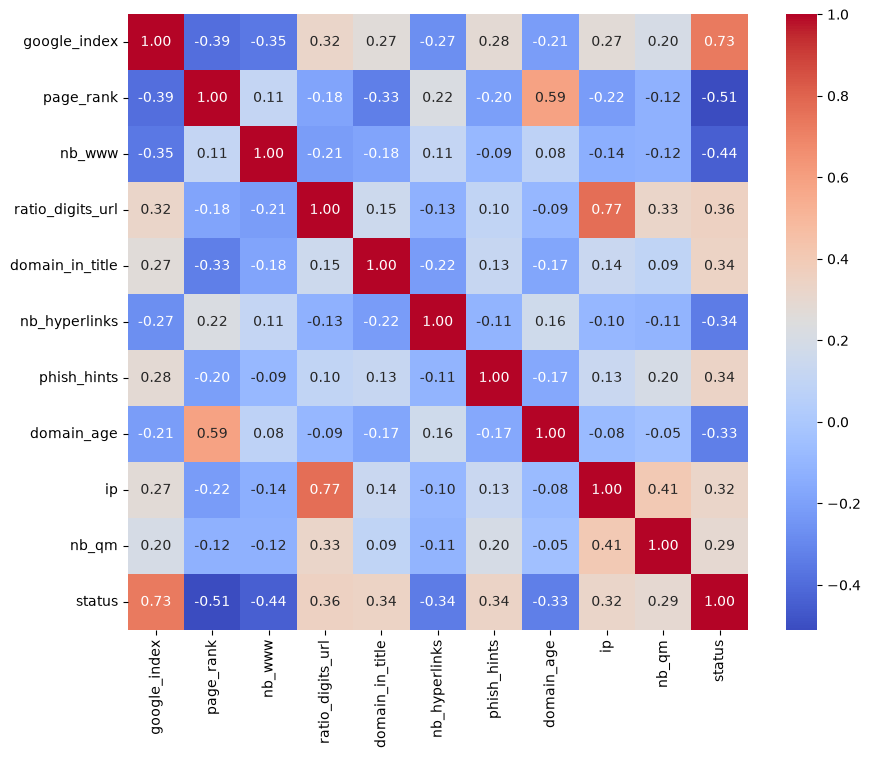

In [28]:
corr_with_target = df.corr()['status'].abs().sort_values(ascending=False)
print(corr_with_target.head(11))

top_features = list(corr_with_target.index[1:11])
print(top_features)

corr = df[top_features + ['status']].corr()
plt.figure(figsize=(10, 8))
sns.heatmap(corr, cmap='coolwarm', annot=True, fmt=".2f")
plt.show()

##### Щодо heatmap кореляцій

Для візуалізації обрано 10 ознак із найбільшим модулем кореляції з цільовою змінною, оскільки матриця 87×87 є нечитабельною. Найсильніший зв'язок має `google_index` (0.73), далі `page_rank` (−0.51) та `nb_www` (−0.44). Від'ємний знак означає, що зі зростанням значення ознаки збільшується ймовірність легітимної сторінки. Також спостерігається кореляція між самими ознаками: `ip` та `ratio_digits_url` (0.77), `page_rank` та `domain_age` (0.59), тобто частина ознак дублює одна одну. Слід пам'ятати, що коефіцієнт кореляції фіксує лише лінійний зв'язок і не доводить причинності.

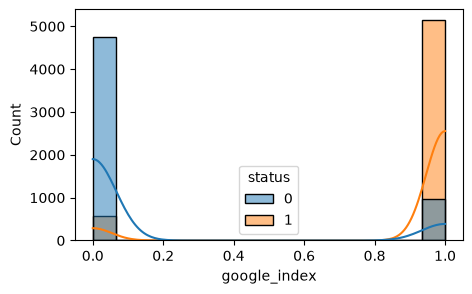

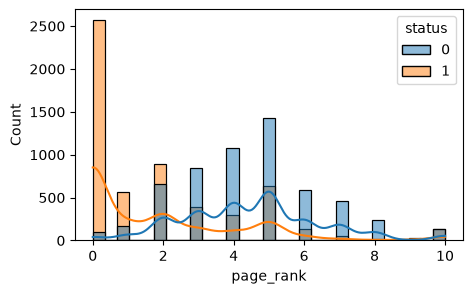

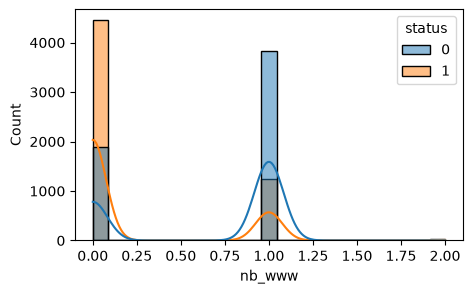

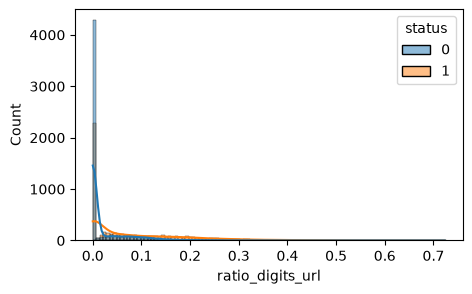

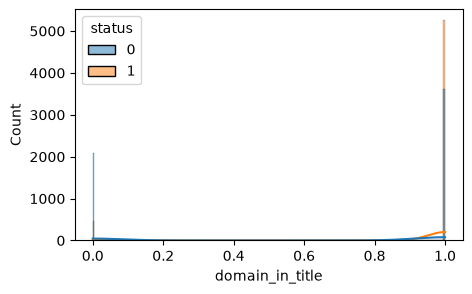

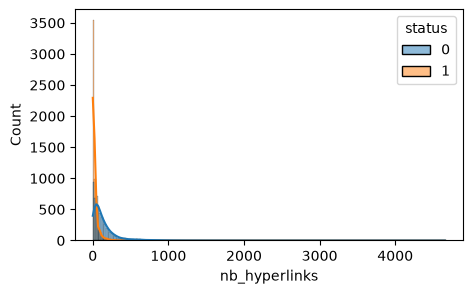

In [29]:
for feature in top_features[:6]:
    plt.figure(figsize=(5, 3))
    sns.histplot(data=df, x=feature, hue='status', kde=True)
    plt.show()

##### Щодо гістограм

Для `google_index` значення 1 мають 89.9% фішингових і лише 16.9% легітимних сторінок. За логікою датасету, значення 1 означає, що сторінки немає в індексі Google. Для `page_rank` значення 0 мають 44.9% фішингових і лише 1.8% легітимних сторінок, тоді як у легітимних сторінок значення розподілені переважно в межах 2–6. Розподіли `nb_hyperlinks` (коефіцієнт асиметрії 7.7) та `ratio_digits_url` сильно скошені праворуч: більшість значень зосереджена біля нуля, а поодинокі сторінки мають до 4 659 посилань. Такі ознаки є корисними для дерев, але потребують масштабування для kNN та SVM.

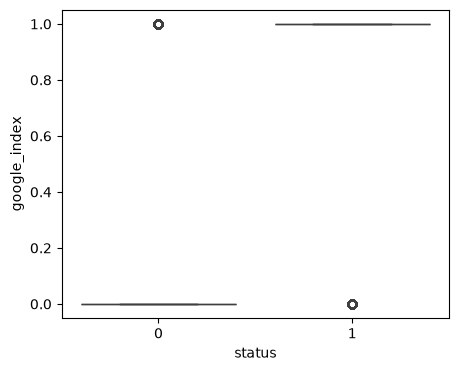

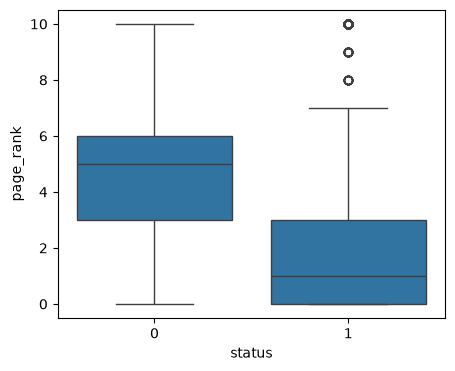

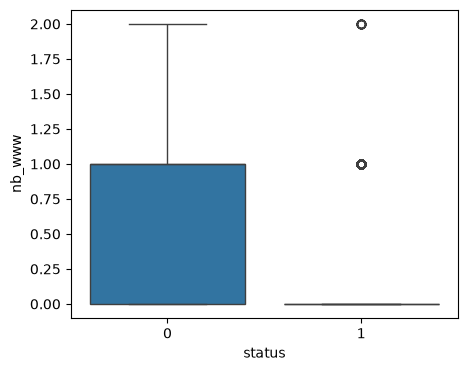

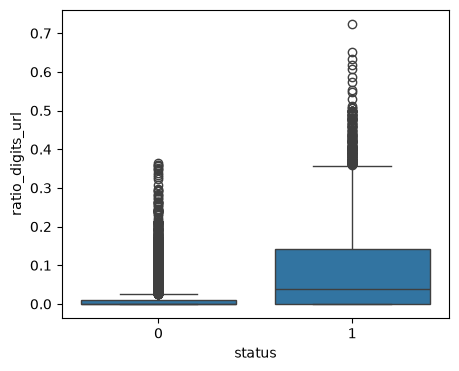

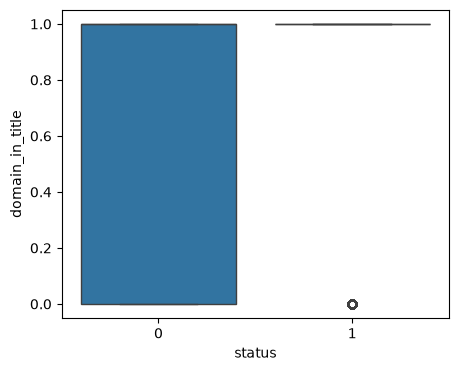

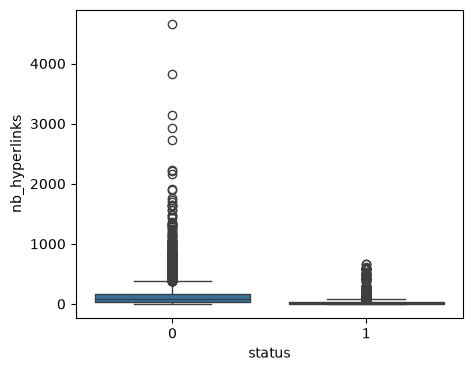

In [30]:
for feature in top_features[:6]:
    plt.figure(figsize=(5, 4))
    sns.boxplot(x='status', y=feature, data=df)
    plt.show()

##### Щодо boxplot-ів

Для `page_rank` медіана становить 5 у легітимних сторінок і 1 у фішингових, а «ящики» майже не перетинаються, тому ця ознака добре розділяє класи. Для `nb_hyperlinks` медіана становить 86 проти 14, причому легітимні сторінки мають значно більше викидів (до 4 659). Для `ratio_digits_url` медіана становить 0 у легітимних і 0.039 у фішингових сторінок: у фішингових адресах частка цифр вища. Для бінарних ознак (`google_index`, `domain_in_title`) boxplot вироджується в горизонтальні лінії та є малоінформативним, тому їх доцільніше аналізувати за гістограмами.

##### Підготовка до навчання

In [31]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=10, stratify=y)

In [32]:
print(X_train.shape, y_train.shape)
print(X_test.shape, y_test.shape)

(9144, 87) (9144,)
(2286, 87) (2286,)


In [33]:
y_train.value_counts()

status
1    4572
0    4572
Name: count, dtype: int64

In [34]:
scaler = StandardScaler()
scaler.fit(X_train)
scaled_X_train = scaler.transform(X_train)
scaled_X_test = scaler.transform(X_test)

##### Пояснення до підготовки даних

Вибірку розділено у співвідношенні 80/20 (9 144 об'єкти для навчання, 2 286 для тестування) із параметром `stratify=y`, який зберігає баланс класів у обох частинах (по 4 572 та по 1 143 об'єкти кожного класу). `random_state` забезпечує відтворюваність результатів. Масштабування необхідне для kNN та SVM, які використовують відстані між об'єктами. Для Decision Tree, Random Forest та AdaBoost воно не потрібне, оскільки дерева порівнюють значення ознак із порогами. Без масштабування точність kNN зменшується з 0.939 до 0.843, а SVM (з параметрами за замовчуванням) з 0.958 до 0.597.

##### Навчання п'яти моделей

In [35]:
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(scaled_X_train, y_train)
knn_pred = knn.predict(scaled_X_test)
print(accuracy_score(y_test, knn_pred))

tree = DecisionTreeClassifier(criterion='gini', max_depth=5, min_samples_leaf=2, random_state=42)
tree.fit(X_train, y_train)
tree_pred = tree.predict(X_test)
print(accuracy_score(y_test, tree_pred))

svm = SVC(C=1.0, gamma='scale', kernel='rbf')
svm.fit(scaled_X_train, y_train)
svm_pred = svm.predict(scaled_X_test)
print(accuracy_score(y_test, svm_pred))

rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)
rf_pred = rf.predict(X_test)
print(accuracy_score(y_test, rf_pred))

ada = AdaBoostClassifier(n_estimators=100, random_state=42)
ada.fit(X_train, y_train)
ada_pred = ada.predict(X_test)
print(accuracy_score(y_test, ada_pred))

0.9391951006124234
0.9295713035870516
0.9575678040244969
0.9671916010498688
0.9387576552930884


##### Підбір гіперпараметрів

{'n_neighbors': 5}


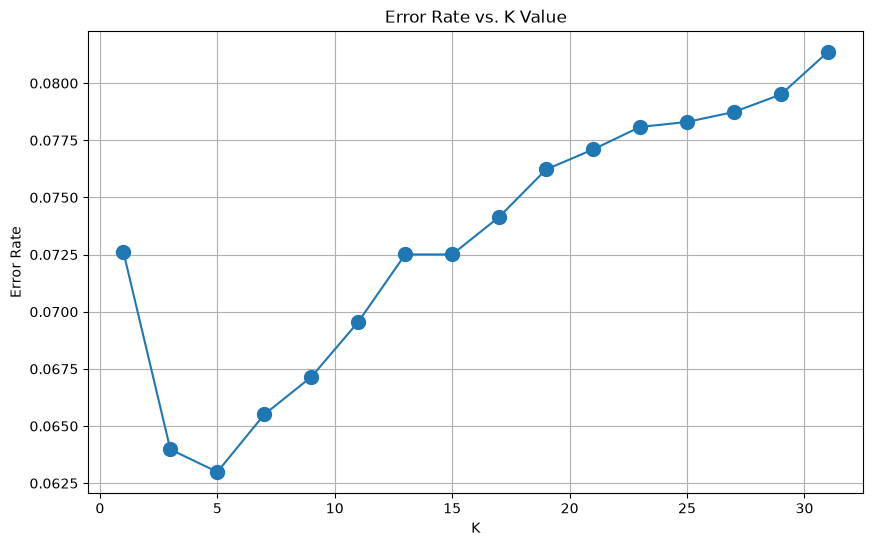

0.9391951006124234


In [40]:
knn_params = {'n_neighbors': range(1, 32, 2)}
knn_grid = GridSearchCV(KNeighborsClassifier(), knn_params, cv=5)
knn_grid.fit(scaled_X_train, y_train)
print(knn_grid.best_params_)

error_rate = 1 - knn_grid.cv_results_['mean_test_score']
plt.figure(figsize=(10, 6))
plt.plot(range(1, 32, 2), error_rate, marker='o', markersize=10)
plt.title('Error Rate vs. K Value')
plt.xlabel('K')
plt.ylabel('Error Rate')
plt.grid()
plt.show()

knn_best_pred = knn_grid.predict(scaled_X_test)
print(accuracy_score(y_test, knn_best_pred))

In [41]:
svm_params = {'C': [0.1, 1, 10, 100], 'gamma': [0.1, 0.01, 0.001, 0.0001], 'kernel': ['rbf']}
svm_grid = GridSearchCV(SVC(), svm_params, cv=5, refit=True)
svm_grid.fit(scaled_X_train, y_train)
print(svm_grid.best_params_)
print(svm_grid.best_score_)

svm_best_pred = svm_grid.predict(scaled_X_test)
print(accuracy_score(y_test, svm_best_pred))

{'C': 10, 'gamma': 0.01, 'kernel': 'rbf'}
0.9595366649398878
0.9597550306211724


##### Пояснення до підбору гіперпараметрів

Гіперпараметри підбиралися на тренувальній вибірці за допомогою 5-кратної крос-валідації, щоб тестова вибірка залишалася незалежною. Для kNN перебиралися непарні значення k від 1 до 31 (непарні, щоб уникнути нічиїх при голосуванні). Мінімальну помилку отримано при k=5: менші значення роблять модель чутливою до шуму, більші надмірно згладжують межу. Для SVM перебиралася сітка C ∈ {0.1, 1, 10, 100} та gamma ∈ {0.1, 0.01, 0.001, 0.0001}. Оптимальними виявилися C=10 та gamma=0.01, що підвищило точність на тесті з 0.958 до 0.960. Оптимальні значення лежать усередині сітки, тому її розширення не потрібне.

##### Порівняння та оцінювання

In [38]:
predictions = {
    'kNN': knn_best_pred,
    'Decision Tree': tree_pred,
    'SVM': svm_best_pred,
    'Random Forest': rf_pred,
    'AdaBoost': ada_pred
}

for name in predictions:
    print(name)
    print(confusion_matrix(y_test, predictions[name]))
    print(classification_report(y_test, predictions[name]))
    print()

results = []
for name in predictions:
    results.append([name,
                    accuracy_score(y_test, predictions[name]),
                    precision_score(y_test, predictions[name]),
                    recall_score(y_test, predictions[name]),
                    f1_score(y_test, predictions[name])])
results_df = pd.DataFrame(results, columns=['Model', 'Accuracy', 'Precision', 'Recall', 'F1'])
results_df = results_df.sort_values('Accuracy', ascending=False)
print(results_df)

kNN
[[1094   49]
 [  90 1053]]
              precision    recall  f1-score   support

           0       0.92      0.96      0.94      1143
           1       0.96      0.92      0.94      1143

    accuracy                           0.94      2286
   macro avg       0.94      0.94      0.94      2286
weighted avg       0.94      0.94      0.94      2286


Decision Tree
[[1089   54]
 [ 107 1036]]
              precision    recall  f1-score   support

           0       0.91      0.95      0.93      1143
           1       0.95      0.91      0.93      1143

    accuracy                           0.93      2286
   macro avg       0.93      0.93      0.93      2286
weighted avg       0.93      0.93      0.93      2286


SVM
[[1099   44]
 [  48 1095]]
              precision    recall  f1-score   support

           0       0.96      0.96      0.96      1143
           1       0.96      0.96      0.96      1143

    accuracy                           0.96      2286
   macro avg       0.96

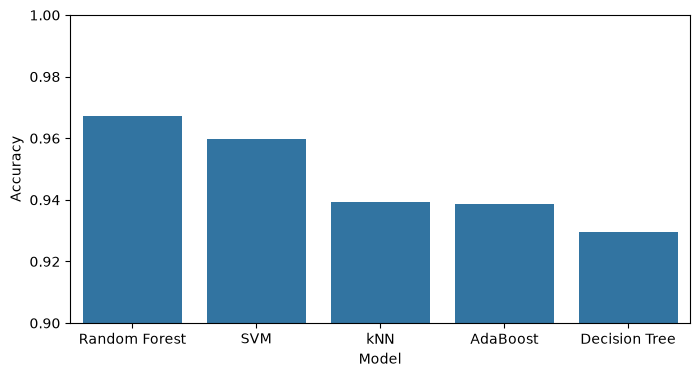

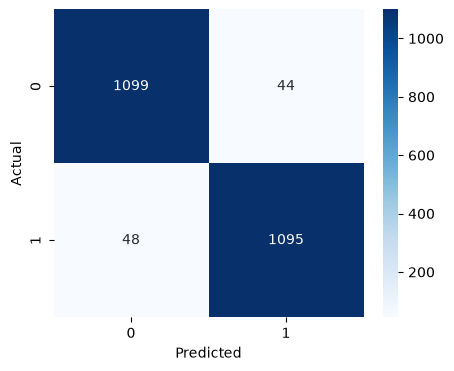

google_index           0.170740
page_rank              0.097845
nb_hyperlinks          0.089513
web_traffic            0.078599
nb_www                 0.042189
domain_age             0.034288
safe_anchor            0.029611
phish_hints            0.027227
longest_word_path      0.026422
ratio_extHyperlinks    0.025763
dtype: float64


In [39]:
plt.figure(figsize=(8, 4))
sns.barplot(x='Model', y='Accuracy', data=results_df)
plt.ylim(0.9, 1.0)
plt.show()

cm = confusion_matrix(y_test, svm_best_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

importances = pd.Series(rf.feature_importances_, index=X.columns)
print(importances.sort_values(ascending=False).head(10))

##### Результати (клас «фішинг»):

| Модель | Accuracy | Precision | Recall | F1 | FP / FN | Усього помилок |
|---|---|---|---|---|---|---|
| Random Forest | 0.967 | 0.975 | 0.959 | 0.967 | 28 / 47 | 75 |
| SVM (C=10, gamma=0.01) | 0.960 | 0.961 | 0.958 | 0.960 | 44 / 48 | 92 |
| kNN (k=5) | 0.939 | 0.956 | 0.921 | 0.938 | 49 / 90 | 139 |
| AdaBoost | 0.939 | 0.951 | 0.925 | 0.938 | 54 / 86 | 140 |
| Decision Tree | 0.930 | 0.950 | 0.906 | 0.928 | 54 / 107 | 161 |

##### Висновки

За результатами експерименту найвищу якість на тестовій вибірці показав Random Forest: accuracy 0.967 при 75 помилках на 2 286 об'єктів, причому лише 28 хибних тривог (precision для фішингу 0.975). Друге місце посів SVM з RBF-ядром (C=10, gamma=0.01): accuracy 0.960 і 92 помилки. Кількість пропущених фішингових сторінок у цих двох моделей майже однакова (47 і 48 FN), тож перевага лісу полягає переважно в меншій кількості хибних тривог. kNN, AdaBoost та Decision Tree показали 0.93–0.94 (139–161 помилка).

Random Forest найкраще підходить для цих даних, оскільки ознаки різнотипні (бінарні прапорці, лічильники, частки), зв'язки між ними нелінійні, а ансамбль дерев усереднює помилки окремих дерев, що зменшує дисперсію й ризик перенавчання. Крім того, він не потребує масштабування й дозволяє оцінити важливість ознак: найвпливовішими виявилися `google_index`, `page_rank`, `nb_hyperlinks` та `web_traffic`, що узгоджується з результатами EDA.